In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Chargement et nettoyage des données

In [3]:
df = pd.read_csv("../data/données.csv", sep = ";")

print(f"Dimensions du dataset : {df.shape}")
print("\nTypes de données originaux :")
print(df.dtypes)
print("\nPremières lignes :")
df.head()

Dimensions du dataset : (73930, 28)

Types de données originaux :
CART             int64
CJEU             int64
PACKSERV         int64
DAV              int64
DECAUTH          int64
CPAI             int64
CARTE            int64
SEXE               str
auto             int64
GAV              int64
PJ               int64
Sante            int64
SEVDOM           int64
ACTION           int64
ASSVIEEURO       int64
CREDCONSO        int64
EPARLOG          int64
ASSMH            int64
CREDHAB          int64
CSL              int64
OBLIGATION       int64
SICAVFCP         int64
EPARBANC         int64
ASSPREVDEC       int64
ASSDEP           int64
CREDRENOV        int64
ASSPREVDECDEP    int64
id               int64
dtype: object

Premières lignes :


,CART,CJEU,PACKSERV,DAV,DECAUTH,CPAI,CARTE,SEXE,auto,GAV,...,CREDHAB,CSL,OBLIGATION,SICAVFCP,EPARBANC,ASSPREVDEC,ASSDEP,CREDRENOV,ASSPREVDECDEP,id
0,0,0,0,1,0,0,0,NaN,1,0,...,0,1,0,0,1,0,0,0,0,1
1,1,0,1,1,0,1,0,NaN,1,1,...,0,1,0,1,1,0,0,0,0,2
2,1,1,1,1,1,1,0,M,0,1,...,0,1,0,0,0,0,0,0,0,3
3,1,0,1,1,1,1,0,F,0,1,...,0,1,0,0,0,0,0,0,0,4
4,1,0,0,1,0,1,0,F,0,1,...,0,1,0,0,0,0,0,0,0,5


In [4]:
sns.set_theme(style="whitegrid")

COL_ID = "id"
COL_SEXE = "SEXE"
PRODUITS = [c for c in df.columns if c not in (COL_ID, COL_SEXE)]
print(f"{len(PRODUITS)} colonnes de produits")

# Vérification de la qualité de base
print("id unique :", df[COL_ID].is_unique)
print("valeurs manquantes (total) :", df.isna().sum().sum())

# Vérification si tous les produits sont binaires (0/1)
valeurs = {c: sorted(df[c].unique()) for c in PRODUITS}
non_binaires = {c: v for c, v in valeurs.items() if set(v) - {0, 1}}
print(non_binaires or "Tous les produits sont binaires (0/1)")

# Analyse de la variable SEXE
print(df[COL_SEXE].value_counts(dropna=False))

26 colonnes de produits
id unique : False
valeurs manquantes (total) : 1283
Tous les produits sont binaires (0/1)
SEXE
M      44481
F      28166
NaN     1283
Name: count, dtype: int64


## 2. Statistiques descriptives

### 2.1 Taux de détention de chaque produit. Il s'agit exactement du support individuel de chaque produit.

,effectif,taux_detention_%
DAV,73233,99.06
CART,63037,85.27
CSL,62506,84.55
PACKSERV,61430,83.09
CPAI,59288,80.19
ASSMH,47985,64.91
DECAUTH,47882,64.77
PJ,32179,43.53
CREDCONSO,32127,43.46
EPARLOG,26795,36.24


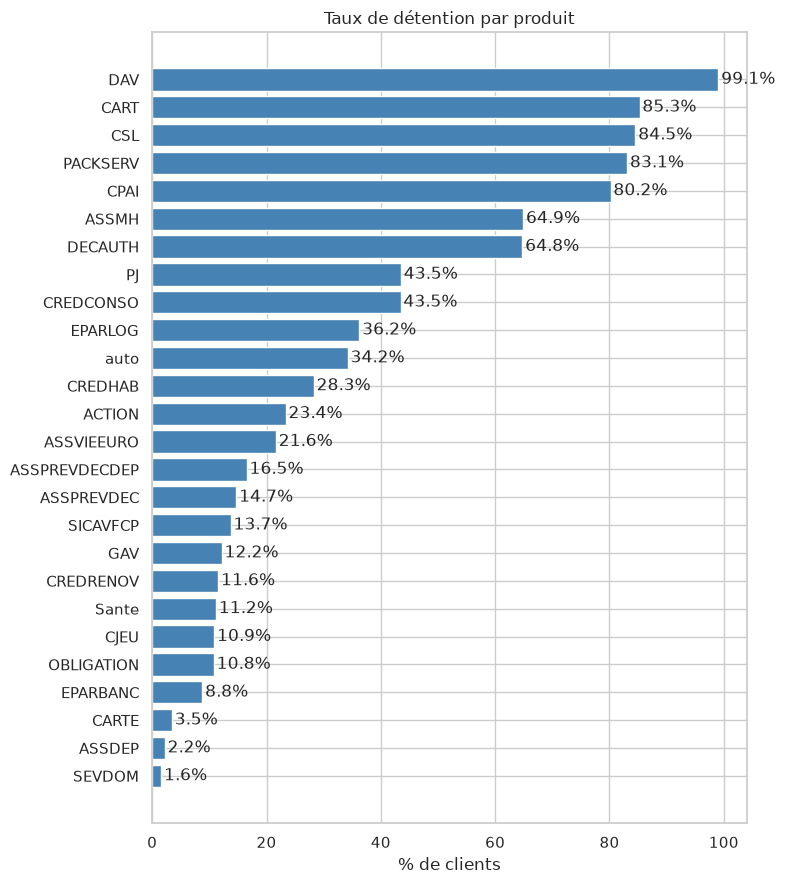

In [5]:
taux = df[PRODUITS].mean().mul(100).sort_values(ascending=False)
tableau = pd.DataFrame({
    "effectif": df[PRODUITS].sum().reindex(taux.index),
    "taux_detention_%": taux.round(2),
})
display(tableau)

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(taux.index[::-1], taux.values[::-1], color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
ax.set_xlabel("% de clients")
ax.set_title("Taux de détention par produit")
plt.tight_layout()
plt.show()

### 2.2 Nombre de produits par client

Moyenne : 9.10 | Médiane : 9
Clients avec 0 ou 1 produit : 0.3%


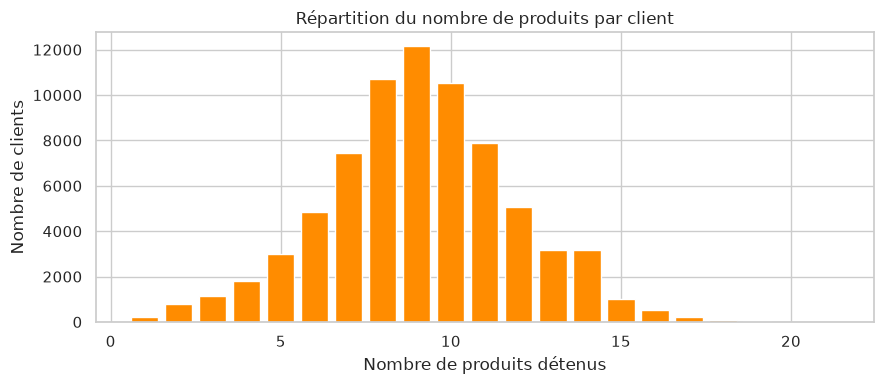

In [6]:
nb_produits = df[PRODUITS].sum(axis=1)
repartition = nb_produits.value_counts().sort_index()

print(f"Moyenne : {nb_produits.mean():.2f} | Médiane : {nb_produits.median():.0f}")
print(f"Clients avec 0 ou 1 produit : {(nb_produits <= 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(repartition.index, repartition.values, color="darkorange")
ax.set_xlabel("Nombre de produits détenus")
ax.set_ylabel("Nombre de clients")
ax.set_title("Répartition du nombre de produits par client")
plt.tight_layout()
plt.show()

### 2.3 Taux de détention par segment (Sexe)

In [7]:
par_sexe = df.groupby(COL_SEXE)[PRODUITS].mean().T.mul(100).round(1)
display(par_sexe)

SEXE,F,M
CART,84.7,86.1
CJEU,11.7,10.4
PACKSERV,82.7,83.5
DAV,98.8,99.3
DECAUTH,62.9,66.1
CPAI,78.5,81.7
CARTE,1.3,4.9
auto,28.7,37.7
GAV,8.9,14.2
PJ,43.9,43.3
